In [ ]:
!pip install -q torch transformers matplotlib numpy pillow

In [2]:
import io
import time
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import transformers
from PIL import Image
from transformers import (
    CLIPModel,
    CLIPProcessor,
    DynamicCache,
    JanusForConditionalGeneration,
    JanusProcessor,
)

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
MODEL_NAME = "deepseek-community/Janus-Pro-1B"
CLIP_NAME = "openai/clip-vit-base-patch32"
IMAGE_URL = "http://images.cocodataset.org/val2017/000000039769.jpg"
SEED = 0
torch.manual_seed(SEED)
print(f"DEVICE = {DEVICE}")

DEVICE = mps


# 1) Native Multimodal Models

A VLM reads images but can only write text. A **native multimodal** model reads and writes
both inside one autoregressive transformer: images are turned into discrete tokens by a VQ
tokenizer, and the language model predicts image tokens the same way it predicts words. Three
designs compete:

| Design | Image input | Image output | Examples |
|---|---|---|---|
| One shared vocabulary | VQ tokens | VQ tokens, same LM head | Chameleon, Emu3, Lumina-mGPT |
| Decoupled encoders | SigLIP features (understanding) | VQ tokens via a separate head (generation) | Janus, Janus-Pro |
| Mixed objectives | continuous patches | diffusion or flow loss on patches inside the LM | Transfusion, Show-o, BAGEL |

Understanding wants semantic features, generation wants features that can be decoded back to
pixels; one tokenizer serving both is the tension Janus resolves by using two. The VQ
quantiser, the classifier-free-guided image-token sampler and the decoupled reading path are
rebuilt below around Janus-Pro-1B and checked against the model.

In [3]:
# Janus-Pro-1B: SigLIP path for understanding, VQ tokens and a head for generation
processor = JanusProcessor.from_pretrained(MODEL_NAME)
model = (
    JanusForConditionalGeneration.from_pretrained(MODEL_NAME, dtype=torch.bfloat16)
    .to(DEVICE)
    .eval()
)
inner = model.model
# Compute parameter counts for each submodule
parts = {
    name: sum(p.numel() for p in child.parameters()) / 1e6
    for name, child in inner.named_children()
}
for name, n in parts.items():
    print(f"  {name:<22} {n:8.1f} M")
# the 72 M-parameter VQ runs in fp32: bf16 distances turn near-ties between codes into rounding
inner.vqmodel.float()
codebook = inner.vqmodel.quantize.embedding.weight
print(
    f"VQ codebook {tuple(codebook.shape)} | generation head -> "
    f"{inner.generation_head.vision_head.out_features} logits | "
    f"text lm_head -> {model.lm_head.out_features} logits"
)

# Download and open the example image
req = urllib.request.Request(IMAGE_URL, headers={"User-Agent": "Mozilla/5.0"})
image = Image.open(io.BytesIO(urllib.request.urlopen(req).read())).convert("RGB")

  vision_model              303.7 M
  aligner                     6.3 M
  vqmodel                    71.9 M
  generation_embeddings       0.1 M
  generation_aligner          4.2 M
  generation_head            37.8 M
  language_model           1442.9 M
VQ codebook (16384, 8) | generation head -> 16384 logits | text lm_head -> 102400 logits


# 2) Generating Image Tokens with Guidance

image (1, 3, 384, 384) -> 576 codes | agreement with Janus VQ 100.0% | 446 distinct codes | reconstruction PSNR 19.8 dB
straight-through: forward equals codebook vectors True, d out/d z = [1.0]


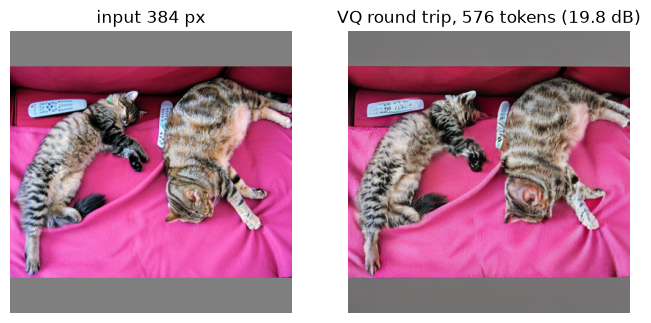

In [4]:
@torch.no_grad()
def vq_encode(pixels: torch.Tensor) -> torch.Tensor:
    """(B, 3, 384, 384) in [-1, 1] -> (B, 576) codes by nearest codebook entry."""
    vq = inner.vqmodel
    z = vq.quant_conv(vq.encoder(pixels))
    # (B, d, h, w) -> (B*h*w, d)
    flat = z.permute(0, 2, 3, 1).reshape(-1, z.shape[1]).float()
    dist = torch.cdist(flat, codebook.float())
    return dist.argmin(dim=1).view(z.shape[0], -1)


def straight_through(
    z: torch.Tensor, e: torch.Tensor, beta: float = 0.25
) -> tuple[torch.Tensor, torch.Tensor]:
    """Quantised output with straight-through gradients, plus codebook + commitment
    loss.
    """
    loss = F.mse_loss(e, z.detach()) + beta * F.mse_loss(z, e.detach())
    return z + (e - z).detach(), loss


# Preprocess image and obtain VQ codes (ours)
pixels = processor.image_processor(image, return_tensors="pt")["pixel_values"].to(
    DEVICE
)
ours = vq_encode(pixels)
with torch.no_grad():
    theirs = inner.vqmodel.encode(pixels).image_tokens.view(1, -1)
    recon = inner.vqmodel.decode(ours).float()
agree = (ours == theirs).float().mean().item()
psnr = 10 * torch.log10(4 / F.mse_loss(recon.clamp(-1, 1), pixels.float())).item()
print(
    f"image {tuple(pixels.shape)} -> {ours.shape[1]} codes | agreement with Janus VQ "
    f"{agree:.1%} | "
    f"{len(ours.unique())} distinct codes | reconstruction PSNR {psnr:.1f} dB"
)

# Quick unit test of straight-through gradients and loss
z = torch.randn(4, 8, requires_grad=True)
e = torch.randn(4, 8)
out, loss = straight_through(z, e)
out.sum().backward()
print(
    f"straight-through: forward equals codebook vectors {torch.allclose(out, e)}, d "
    f"out/d z = {z.grad.unique().tolist()}"
)

# Show input and VQ reconstruction side by side
to_img = lambda t: ((t.float().clamp(-1, 1) + 1) / 2)[0].permute(1, 2, 0).cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, im, title in zip(
    axes,
    [pixels, recon],
    ["input 384 px", f"VQ round trip, 576 tokens ({psnr:.1f} dB)"],
):
    ax.imshow(to_img(im))
    ax.set_title(title)
    ax.axis("off")
plt.show()

In [5]:
def prompt_ids(prompt: str) -> torch.Tensor:
    """Chat-formatted generation prompt ending in the begin-of-image token, (1,
    seq_len).
    """
    return processor(text=[prompt], generation_mode="image", return_tensors="pt")[
        "input_ids"
    ].to(DEVICE)


@torch.no_grad()
def generate_image_tokens(
    prompt: str,
    scale: float,
    temperature: float = 1.0,
    greedy: bool = False,
    num_tokens: int = 576,
    seed: int = SEED,
) -> torch.Tensor:
    """Classifier-free-guided raster-order sampling of image codes, (1, num_tokens)."""
    cond = prompt_ids(prompt)
    uncond = cond.clone()
    boi = model.generation_config.generation_kwargs["boi_token_id"]
    keep = (uncond == model.generation_config.bos_token_id) | (uncond == boi)
    uncond[~keep] = model.generation_config.pad_token_id
    embeds = model.get_input_embeddings()(torch.cat([cond, uncond]))
    cache = DynamicCache()
    generator = torch.Generator(device="cpu").manual_seed(seed)
    tokens = []
    for _ in range(num_tokens):
        out = inner.language_model(
            inputs_embeds=embeds, past_key_values=cache, use_cache=True
        )
        logits = inner.generation_head(out.last_hidden_state[:, -1]).float()
        guided = logits[1] + scale * (logits[0] - logits[1])
        if greedy:
            nxt = guided.argmax()
        else:
            probs = torch.softmax(guided / temperature, dim=-1).cpu()
            nxt = torch.multinomial(probs, 1, generator=generator)[0].to(DEVICE)
        tokens.append(nxt)
        # the same sampled code feeds both the conditional and unconditional streams
        embeds = model.prepare_embeddings_for_image_generation(
            nxt.view(1, 1).repeat(2, 1)
        )
    return torch.stack(tokens).view(1, -1)


# Generate 48 greedy image tokens with our sampler
start = time.time()
ours = generate_image_tokens(
    "a red apple on a wooden table", scale=5.0, greedy=True, num_tokens=48
)
print(f"48 greedy tokens in {time.time() - start:.1f} s")
# Get reference tokens from model.generate for comparison
inputs = processor(
    text=["a red apple on a wooden table"], generation_mode="image", return_tensors="pt"
).to(DEVICE)
with torch.no_grad():
    # an explicit DynamicCache sidesteps the static-cache path, broken in this transformers version
    ref = model.generate(
        **inputs,
        generation_mode="image",
        do_sample=False,
        guidance_scale=5.0,
        past_key_values=DynamicCache(),
    )
print(
    "first 48 tokens equal to model.generate(greedy, guidance 5): "
    f"{torch.equal(ours[0], ref[0, :48])}"
)

48 greedy tokens in 0.4 s


first 48 tokens equal to model.generate(greedy, guidance 5): True


Same weights, two guidance scales, two prompts, sampled at temperature 1. CLIP ViT-B/32 scores
how well each decoded image matches its prompt (cosine similarity × 100), a standard automatic
measure of prompt adherence.

guidance 1 | a red apple on a wooden table            | CLIP 23.5 | 33 s


guidance 1 | a lighthouse on a cliff at sunset, oil p | CLIP 30.3 | 29 s


guidance 5 | a red apple on a wooden table            | CLIP 27.1 | 26 s


guidance 5 | a lighthouse on a cliff at sunset, oil p | CLIP 33.7 | 24 s
mean CLIP score at guidance 1: 26.9
mean CLIP score at guidance 5: 30.4


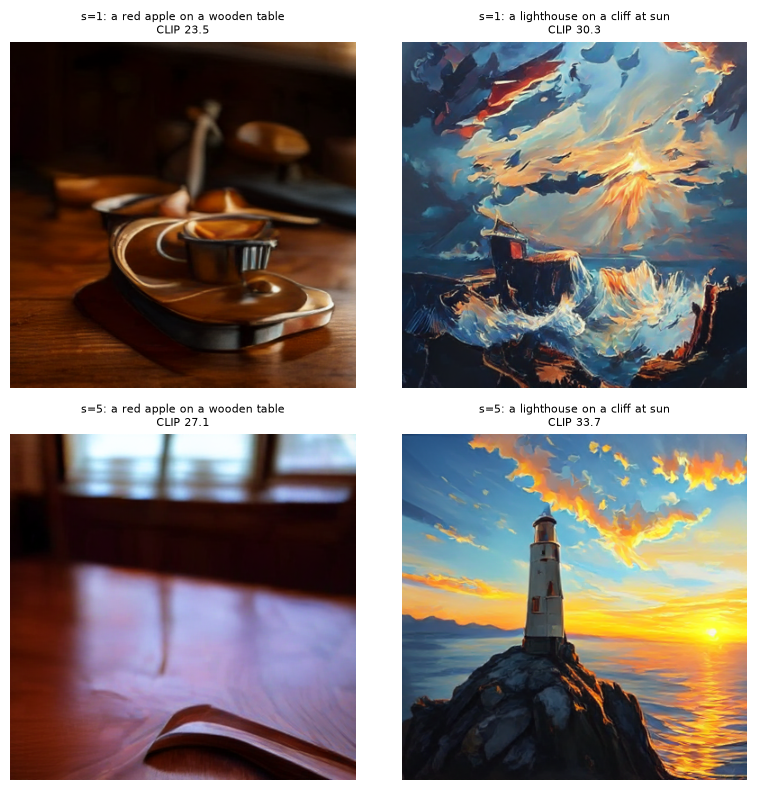

In [6]:
clip = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)


@torch.no_grad()
def clip_score(images: list[np.ndarray], texts: list[str]) -> list[float]:
    """100 * cosine(image, text) with CLIP ViT-B/32."""
    batch = clip_proc(
        text=texts,
        images=[Image.fromarray((im * 255).astype(np.uint8)) for im in images],
        return_tensors="pt",
        padding=True,
    ).to(DEVICE)
    out = clip(**batch)
    sims = F.cosine_similarity(out.image_embeds, out.text_embeds)
    return (100 * sims).tolist()


# Generate images at two guidance scales and score with CLIP
PROMPTS = [
    "a red apple on a wooden table",
    "a lighthouse on a cliff at sunset, oil painting",
]
grid, scores = {}, {}
for scale in (1.0, 5.0):
    for prompt in PROMPTS:
        start = time.time()
        codes = generate_image_tokens(prompt, scale)
        with torch.no_grad():
            img = to_img(inner.vqmodel.decode(codes))
        grid[(scale, prompt)] = img
        scores[(scale, prompt)] = clip_score([img], [prompt])[0]
        print(
            f"guidance {scale:.0f} | {prompt[:40]:<40} | CLIP "
            f"{scores[(scale, prompt)]:.1f} | {time.time() - start:.0f} s"
        )
for scale in (1.0, 5.0):
    print(
        f"mean CLIP score at guidance {scale:.0f}: "
        f"{np.mean([scores[(scale, p)] for p in PROMPTS]):.1f}"
    )

# Display the generated images and their CLIP scores
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for r, scale in enumerate((1.0, 5.0)):
    for c, prompt in enumerate(PROMPTS):
        axes[r, c].imshow(grid[(scale, prompt)])
        axes[r, c].set_title(
            f"s={scale:.0f}: {prompt[:30]}\nCLIP {scores[(scale, prompt)]:.1f}",
            fontsize=8,
        )
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()

# 3) Different Encoder for Reading

For understanding, Janus never uses the VQ codes. The image goes through SigLIP and the
understanding aligner, producing continuous vectors that are spliced into the prompt like any
VLM; the text `lm_head` then answers. The two paths share only the transformer in the middle.

In [7]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": "Describe this image in one sentence."},
        ],
    }
]
# Build chat-formatted prompt and pack inputs with image
text = processor.apply_chat_template(messages, add_generation_prompt=True)
inputs = processor(text=[text], images=[image], return_tensors="pt").to(
    DEVICE, torch.bfloat16
)
# Compute image features and generate the textual answer
with torch.no_grad():
    und = inner.get_image_features(inputs["pixel_values"])
    und = und.pooler_output if hasattr(und, "pooler_output") else und
    out = model.generate(
        **inputs, max_new_tokens=40, do_sample=False, generation_mode="text"
    )
# Decode generated tokens and print the model's answer
answer = processor.decode(
    out[0, inputs["input_ids"].shape[1] :], skip_special_tokens=True
)
print(
    f"understanding tokens: {tuple(und.shape)} continuous | generation tokens: (1, "
    "576) integer codes"
)
print(f"Janus-Pro: {answer.strip()}")

understanding tokens: (1, 576, 2048) continuous | generation tokens: (1, 576) integer codes
Janus-Pro: This image shows two cats lying on a pink couch, with a remote control placed between them.


# Summary

- **Tokenizer quality caps generation.** A 16× VQ with a small codebook loses texture; recent
  models use larger codebooks with lookup-free or finite-scalar quantisation (MAGVIT-v2, FSQ),
  or skip discrete codes and generate continuous latents with a diffusion head (Transfusion,
  BAGEL, Janus-Flow).
- **Sequence length.** 576 sequential steps per 384 px image is slow next to a 20-step diffusion
  sampler; higher resolutions push raster AR to thousands of tokens, which is why parallel
  decoding (MaskGIT-style, next-scale prediction in VAR) is attractive.
- **Guidance.** CFG doubles the per-step cost; the unconditional stream must see the same
  generated tokens. Too high a scale saturates colours and collapses diversity.
- **Shared vs decoupled.** One vocabulary (Chameleon, Emu3) is the simplest training recipe and
  allows arbitrary interleaving; decoupled encoders (Janus) score better on understanding
  benchmarks at small scale because SigLIP features are more semantic than VQ codes.
- **Training data** is interleaved image–text documents plus text-to-image pairs; the loss is
  next-token cross-entropy over both modalities, usually reweighted per modality.

| Piece | Built | Checked against |
|---|---|---|
| VQ quantisation | nearest codebook entry on encoder latents | Janus `vqmodel.encode` codes; reconstruction PSNR |
| Straight-through + commitment loss | $z + \operatorname{sg}(e - z)$ | forward value and unit gradient |
| CFG image-token sampler | two streams, $\ell_\varnothing + s(\ell_c - \ell_\varnothing)$, raster order | `generate(generation_mode="image")` greedy tokens; CLIP score vs guidance |
| Decoupled reading | SigLIP + aligner, text head | captions the input photo |